In [4]:
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- settings ----------
INPUT_FILE = "Bandgap_ML.csv"
OUTPUT_FILE = "Bandgap.csv"
GAP_COL = "band_gap"            # the ML-corrected gap
GAP_MIN = 1.5                   # eV, keep gaps >= this
GAP_MAX = 3.0                   # eV, keep gaps <= this
REQUIRE_DIRECT = False          # True = keep only direct-gap materials
REQUIRE_IN_DOMAIN = False       # True = also drop materials with elements the training data hardly contains
# ------------------------------

HERE = Path.cwd()
candidates = [HERE / "data", HERE, HERE / "notebook" / "data" / "data", HERE / "notebook" / "data"]
DATA_DIR = next((p for p in candidates if (p / INPUT_FILE).exists()), None)
assert DATA_DIR is not None, f"{INPUT_FILE} not found. Run Bandgap_ML.ipynb first."
IN_PATH = DATA_DIR / INPUT_FILE
OUT_PATH = DATA_DIR / OUTPUT_FILE
REMOVED_PATH = DATA_DIR / "Bandgap_removed.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(IN_PATH)
assert GAP_COL in df.columns, f"column {GAP_COL} not found in {INPUT_FILE}"
print("Read", len(df), "materials from", IN_PATH)

Read 17384 materials from c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap_ML.csv


Input materials          : 17,384
Gap below 1.5 eV        : 2,397
Gap above 3.0 eV        : 8,193
Kept (1.5-3.0 eV)       : 6,794  (4,884 different formulas)
Gap source of kept rows  : {'ML': 6271, 'experiment': 523}
Stability of kept rows   : {'near-stable': 3706, 'stable': 3088}


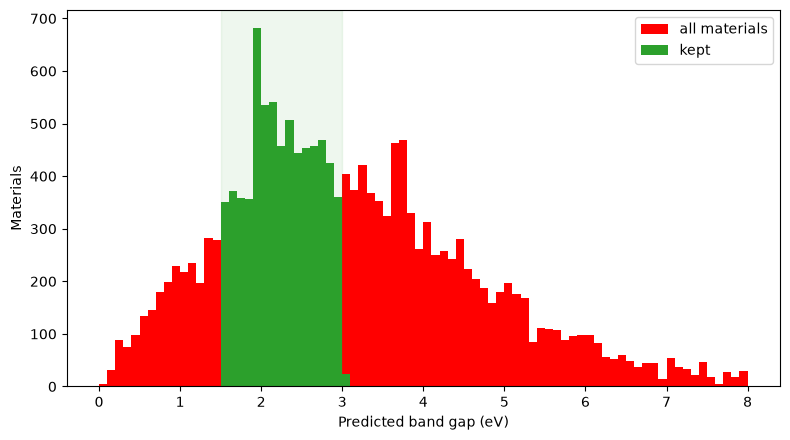

In [5]:
below = df[GAP_COL] < GAP_MIN
above = df[GAP_COL] > GAP_MAX
keep = ~(below | above)

if REQUIRE_DIRECT:
    if "gap_type" in df.columns:
        direct = df["gap_type"].astype(str).str.lower().eq("direct")
    else:
        direct = df["is_gap_direct"].astype(str).str.lower().eq("true")
    keep &= direct

if REQUIRE_IN_DOMAIN and "in_domain" in df.columns:
    keep &= df["in_domain"].astype(str).str.lower().eq("true")

out = df[keep].reset_index(drop=True)
removed = df[~keep].copy()
removed["removed_reason"] = np.select(
    [below[~keep], above[~keep]],
    [f"gap < {GAP_MIN}", f"gap > {GAP_MAX}"],
    default="direct/domain filter")

print(f"Input materials          : {len(df):,}")
print(f"Gap below {GAP_MIN} eV        : {int(below.sum()):,}")
print(f"Gap above {GAP_MAX} eV        : {int(above.sum()):,}")
print(f"Kept ({GAP_MIN}-{GAP_MAX} eV)       : {len(out):,}  ({out['formula'].nunique():,} different formulas)")
if "band_gap_source" in out.columns:
    print("Gap source of kept rows  :", out["band_gap_source"].value_counts().to_dict())
if "stability_class" in out.columns:
    print("Stability of kept rows   :", out["stability_class"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 8, 81)
ax.hist(df[GAP_COL], bins=bins, color="red", label="all materials")
ax.hist(out[GAP_COL], bins=bins, color="tab:green", label="kept")
ax.axvspan(GAP_MIN, GAP_MAX, color="tab:green", alpha=0.08)
ax.set_xlabel("Predicted band gap (eV)"); ax.set_ylabel("Materials"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "bandgap_screen.png", dpi=200); plt.show()

In [7]:
out.to_csv(OUT_PATH, index=False)
removed.to_csv(REMOVED_PATH, index=False)

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": INPUT_FILE, "output_file": OUTPUT_FILE,
    "gap_window_eV": [GAP_MIN, GAP_MAX],
    "require_direct": REQUIRE_DIRECT, "require_in_domain": REQUIRE_IN_DOMAIN,
    "rows_in": int(len(df)), "rows_kept": int(len(out)), "rows_removed": int(len(removed)),
}
(DATA_DIR / "Bandgap_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH, "| exists:", OUT_PATH.exists(), "| rows:", len(out))
print("Saved:", REMOVED_PATH, "| exists:", REMOVED_PATH.exists())

Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap.csv | exists: True | rows: 6794
Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap_removed.csv | exists: True
